In [ ]:
from torchaudio.transforms import MelSpectrogram

import datasets
import matplotlib.pyplot as plt
import torch
import soundfile as sf

ModuleNotFoundError: No module named 'src'

In [12]:
def audio_augmentation(audio: torch.Tensor) -> torch.Tensor:
    audio = audio.clone()

    if torch.rand(()).item() < 0.5:
        gain = torch.empty((), device=audio.device).uniform_(0.8, 1.2)

        audio = audio * gain

    if torch.rand(()).item() < 0.3:
        signal_rms = audio.square().mean().sqrt()

        snr_db = torch.empty((), device=audio.device).uniform_(20.0, 35.0)

        noise = torch.randn_like(audio)

        noise_rms = noise.square().mean().sqrt()
        noise = noise / noise_rms.clamp_min(1e-8)

        target_noise_rms = signal_rms * torch.pow(10.0, -snr_db / 20.0)

        audio = audio + noise * target_noise_rms

    return audio

def log_mel_augmentation(mel_audio: torch.Tensor) -> torch.Tensor:
    mel_audio = mel_audio.clone()

    n_mels, time_steps = mel_audio.shape

    mask_value = mel_audio.mean()

    if torch.rand(()) < 0.5:
        max_width = min(9, n_mels)

        if max_width > 0:
            width = torch.randint(1, max_width + 1, ()).item()
            start = torch.randint(0, n_mels - width + 1, ()).item()

            mel_audio[start:start + width, :] = mask_value

    if torch.rand(()) < 0.5:
        max_width = min(30, int(time_steps * 0.05))

        if max_width > 0:
            width = torch.randint(1, max_width + 1, ()).item()
            start = torch.randint(0, time_steps - width + 1, ()).item()

            mel_audio[:, start:start + width] = mask_value

    return mel_audio

In [2]:
# experiments setup
_SAVE_SAMPLE_TO_FILE = True

SAMPLE_FILE = ".data/sample.wav"

DATASET_PATH = "openslr/librispeech_asr"
DATASET_NAME = "clean"
DATASET_SPLIT = "train.100"

SR = 16000
N_FFT = 400
HOP_LENGTH = 160
N_MELS = 80

In [3]:
dataset = datasets.load_dataset(DATASET_PATH, DATASET_NAME, split=DATASET_SPLIT, streaming=True)
sample = next(iter(dataset))

In [4]:
print(sample.keys(), end="\n\n")

audio, text = sample['audio'], sample['text']
print(f"Audio: {audio.keys()}, {audio}")
print(f"Text: {text}")

audio_tensor = torch.as_tensor(audio['array'], dtype=torch.float32)

if _SAVE_SAMPLE_TO_FILE:
    sf.write(SAMPLE_FILE, audio["array"], audio["sampling_rate"])

dict_keys(['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])

Audio: dict_keys(['path', 'array', 'sampling_rate']), {'path': '374-180298-0000.flac', 'array': array([ 7.01904297e-04,  7.32421875e-04,  7.32421875e-04, ...,
       -2.74658203e-04, -1.83105469e-04, -3.05175781e-05], shape=(232480,)), 'sampling_rate': 16000}
Text: CHAPTER SIXTEEN I MIGHT HAVE TOLD YOU OF THE BEGINNING OF THIS LIAISON IN A FEW LINES BUT I WANTED YOU TO SEE EVERY STEP BY WHICH WE CAME I TO AGREE TO WHATEVER MARGUERITE WISHED


In [14]:
def plot_audio_wave(audio_tensor):
    plt.figure(figsize=(14, 3))
    plt.plot(audio_tensor.numpy())
    plt.xlabel("Samples")
    plt.ylabel("Amplitude")
    plt.title("Audio Waveform")
    plt.grid()
    plt.show()


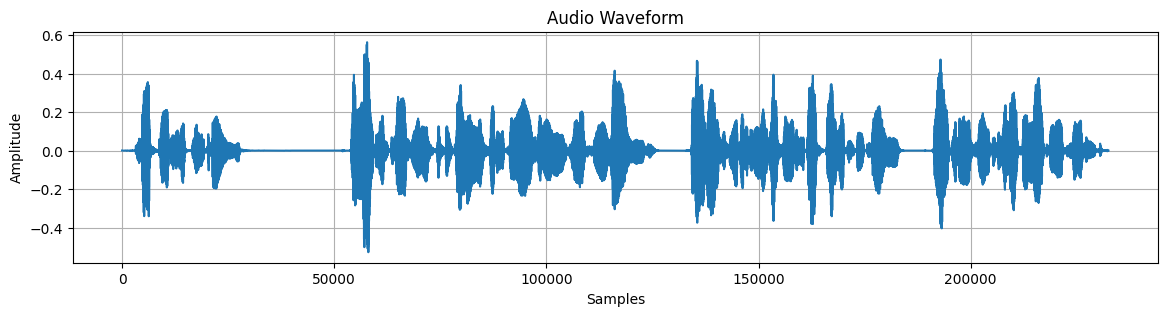

In [15]:
plot_audio_wave(audio_tensor)

In [6]:
mel_transformer = MelSpectrogram(
    sample_rate=SR,
    n_fft=N_FFT,
    win_length=N_FFT,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    power=2.0
)

audio_mel_spectr = mel_transformer(audio_tensor)
audio_log_mel = torch.log(audio_mel_spectr.clamp_min(1e-6))

print(f"Shape of mel spectr: {audio_mel_spectr.shape}")
print(f"Shape of log-mel spectr: {audio_log_mel.shape}")

Shape of mel spectr: torch.Size([80, 1454])
Shape of log-mel spectr: torch.Size([80, 1454])


In [7]:
def plot_mel_spector(mel_spectors, title, label, x_label, y_label):
    plt.figure(figsize=(12, 5))

    plt.imshow(
        mel_spectors.cpu().numpy(),
        origin="lower",
        aspect="auto",
        cmap="magma",
        extent=[0, mel_spectors.shape[-1] * HOP_LENGTH / SR, 0, N_MELS]
    )

    plt.colorbar(label=label)
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)

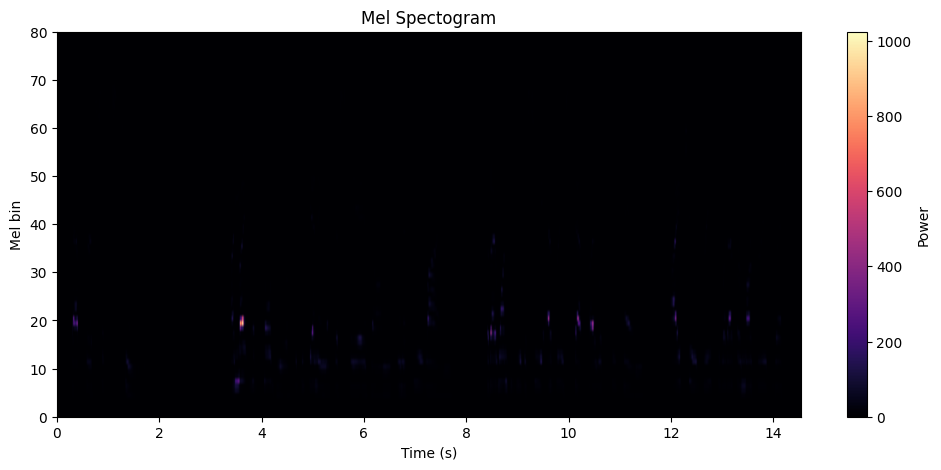

In [8]:
plot_mel_spector(audio_mel_spectr, "Mel Spectogram", "Power", "Time (s)", "Mel bin")

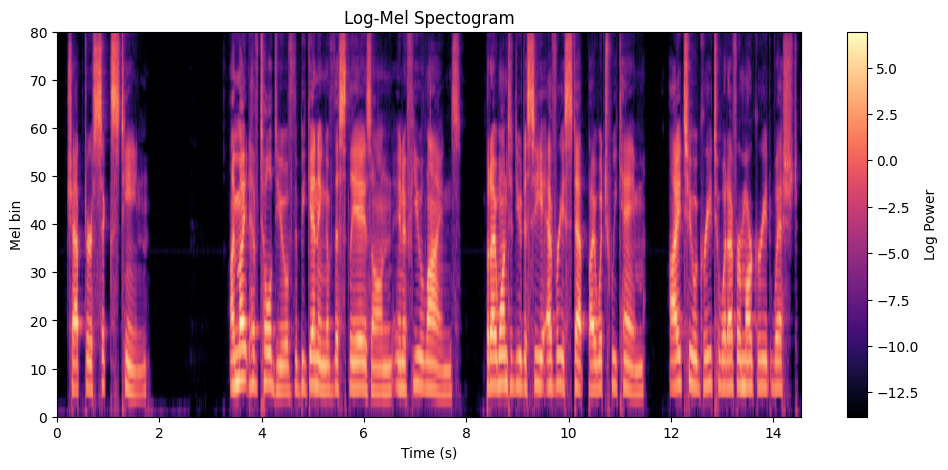

In [9]:
plot_mel_spector(audio_log_mel, "Log-Mel Spectogram", "Log Power", "Time (s)", "Mel bin")

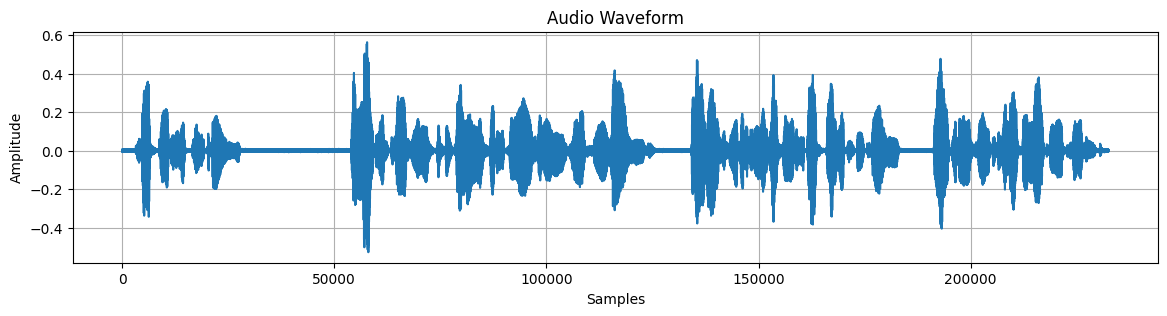

In [16]:
augm_tensor = audio_augmentation(audio_tensor)
plot_audio_wave(augm_tensor)

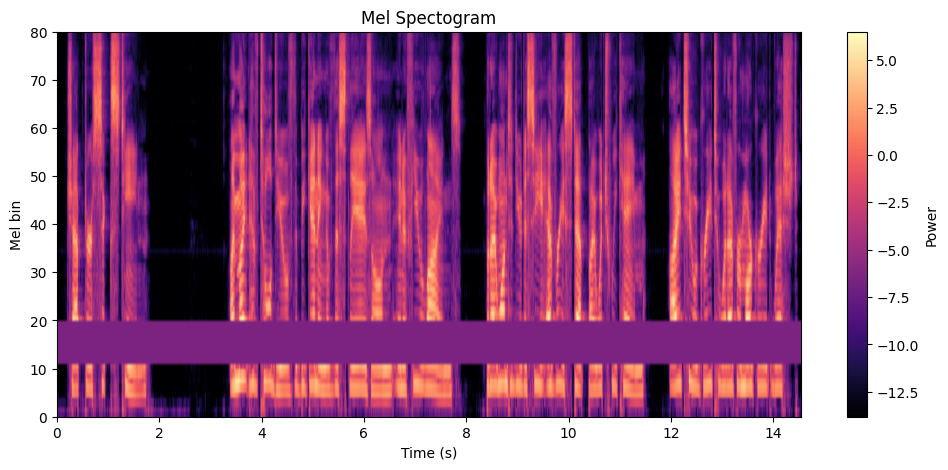

In [22]:
audio_mel_spectr = mel_transformer(audio_tensor)
audio_log_mel = torch.log(audio_mel_spectr.clamp_min(1e-6))
aumg_log_mel = log_mel_augmentation(audio_log_mel)
plot_mel_spector(aumg_log_mel, "Mel Spectogram", "Power", "Time (s)", "Mel bin")